# Gaussian-process priors and information field theory

virgil's Gaussian-process (GP) image prior, [`GaussianField`][virgil.fields.GaussianField], takes its main ideas from information field theory (IFT), developed by Torsten Enßlin's group and implemented in their package NIFTy. IFT casts Bayesian inference on fields in the language of statistical field theory (Hamiltonian, propagator, source, free energy), which connects it to physics methods such as perturbation theory and extends naturally to non-Gaussian, nonlinear problems. For Gaussian priors, though, many of its objects are those of Gaussian-process regression under other names (e.g. Rasmussen & Williams 2006), and a reader fluent in one vocabulary can struggle to recognize the same ideas in the other. This page translates between them, for readers who know GPs and want to follow the IFT papers, and for those who met IFT first. It covers:

1. what virgil does, in GP terminology;
2. a dictionary from IFT terms to GP terminology, with the corresponding virgil code;
3. where virgil differs from NIFTy;
4. what to read next.

For a worked example, see [Imaging, part 3](imaging_gp.md).

**In brief.** virgil puts a Gaussian-process prior on the logarithm of the image's brightness. Its covariance is a Matérn-like kernel with an amplitude σ and a correlation length ℓ in milliarcseconds, applied cheaply in the image's cosine (DCT) basis, where it is diagonal. The fitted parameters are standard-normal latents that this covariance maps to the image, and σ and ℓ are chosen by maximizing the Bayesian evidence. In IFT's words: a "signal field" with a "power spectrum", in "standardized coordinates", with hyperparameters from the "partition function".

## What virgil does

### The image

An [`Image`][virgil.models.Image] has a log-brightness $\eta_i$ in each pixel $i$. The pixel fluxes are

$$b_i = F \, \frac{e^{\eta_i}}{\sum_j e^{\eta_j}},$$

the softmax of η over the pixels in the image's support, where F is the total flux (the `flux` parameter). So every pixel is positive whatever η is, and adding the same constant to every $\eta_i$ leaves the image unchanged.

### The prior

`GaussianField` makes η a Gaussian process about a template image μ:

$$\eta \sim \mathcal{N}\left(\log\left(\frac{\mu}{\max\mu} + \epsilon\right),\ \Sigma\right).$$

The template μ is any positive image you supply (`mean`), such as a Gaussian of roughly the right size; ε (`mean_floor`, default $10^{-3}$) keeps the logarithm finite where it is zero. With no template the prior mean is zero, a flat image.

The covariance Σ is **approximately stationary**: away from the edges, the covariance of two pixels' log-brightness depends only on their separation. Near the edges it departs from this, because the edges reflect (see below). Its two hyperparameters are both defined in the image:

- **σ** (`sigma`) is the typical departure of η from the template, in log-brightness: σ² is the variance of η averaged over pixels. A departure of 1 changes a pixel's relative brightness by a factor of e ≈ 2.7.
- **ℓ** (`length_mas`) is the correlation length in milliarcseconds. Pixels much closer than ℓ brighten and fade together; pixels much farther apart vary independently.

The kernel is close to Matérn (the next section explains the difference). ℓ is the Matérn length scale 1/κ, not the separation at which the correlation falls to 1/e: for the default `order=2`, the continuum correlation is about 0.6 at ℓ, 0.3 at 2ℓ and 0.1 at 3ℓ. A prior with ℓ below the interferometer's resolution allows structure the data cannot constrain; the evidence (below) decides.

Here is what that means for images. Each figure shows three draws from the prior, with σ = 1 and no template, and below them cuts through a hundred draws of η along the central column and row (draw 1 in bold).

In [1]:
import sys
from pathlib import Path

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt

repo_root = Path.cwd()
if not (repo_root / "src").exists():
    repo_root = repo_root.parent
if str(repo_root / "src") not in sys.path:
    sys.path.insert(0, str(repo_root / "src"))

from virgil.fields import GaussianField
from virgil.plotting import plot_field_draws

# Prior draws on a 64 x 64 grid of 0.5 mas pixels, all from the same latents z.
h, key = 0.5, jax.random.PRNGKey(0)


def prior(length_mas, order=2):
    return GaussianField(
        jnp.zeros((64, 64)), sigma=1.0, length_mas=length_mas, order=order
    )

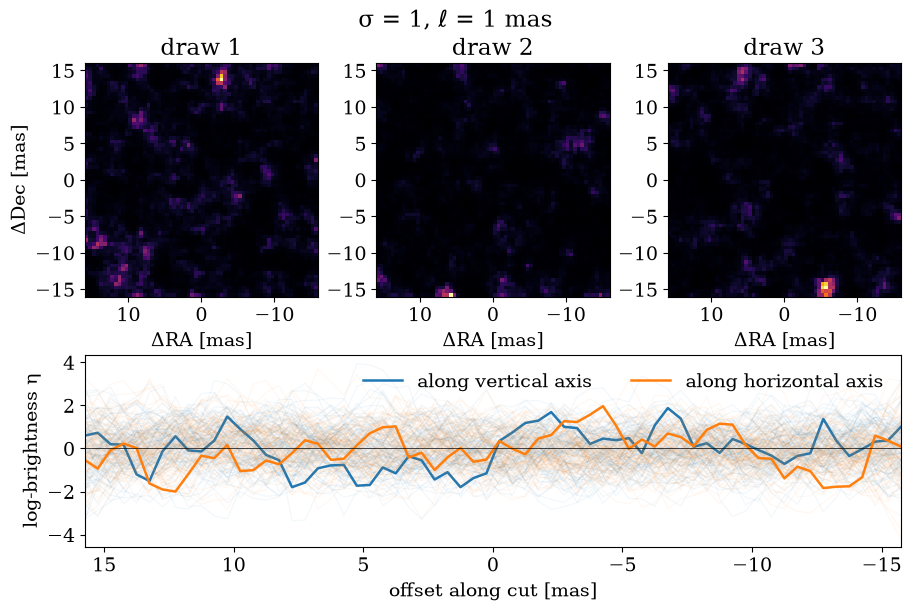

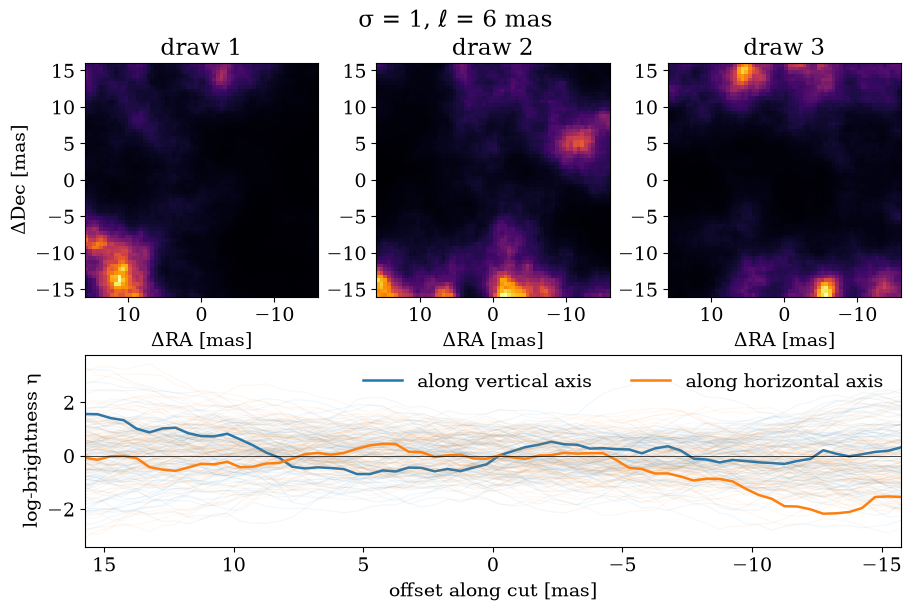

In [2]:
for length in (1.0, 6.0):
    plot_field_draws(prior(length), h, key, title=rf"σ = 1, $\ell$ = {length:g} mas")
    plt.show()

The two figures share their latents z, so the bright patches sit in the same places. At ℓ = 1 mas the image is mottled pixel to pixel; at ℓ = 6 mas it is a few broad patches and the cuts wander slowly. The brightest patches often lie at the edges, where the reflecting boundary (below) raises the variance.

ℓ can also be a pair, `(ℓ_row, ℓ_col)`: correlated over ℓ_row down each column and over ℓ_col along each row.

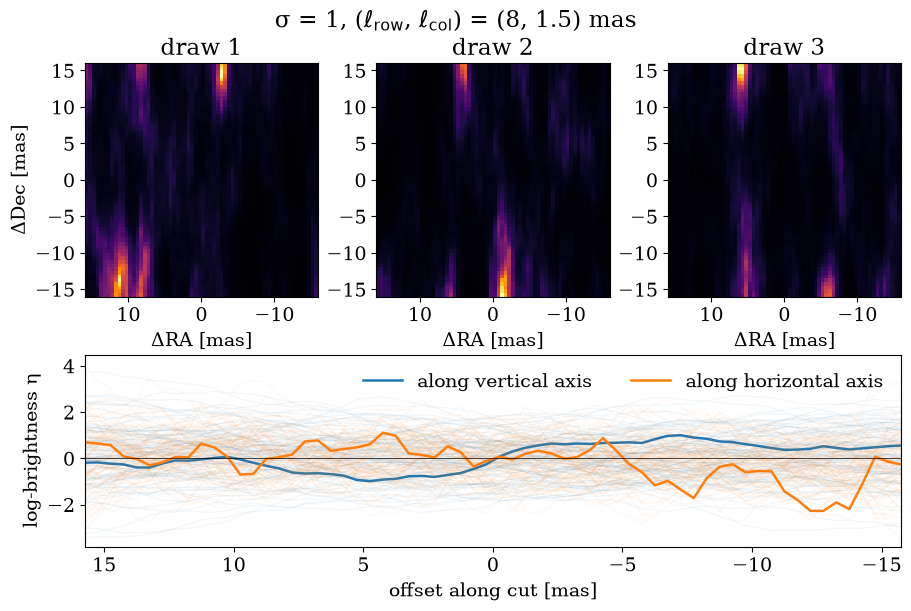

In [3]:
plot_field_draws(
    prior(jnp.array([8.0, 1.5])), h, key,
    title=r"σ = 1, ($\ell_\mathrm{row}$, $\ell_\mathrm{col}$) = (8, 1.5) mas",
)
plt.show()

The draws are streaks running north–south, and the cut along the vertical axis is smoother than the cut along the horizontal.

### Computing with it

An n × m image has nm pixels, so Σ is an nm × nm matrix, expensive to store and more so to invert. A stationary covariance is diagonal in a Fourier basis, and virgil's nearly stationary one is exactly diagonal in a cosine basis. Its diagonal there is the **power spectrum**, the Fourier transform of the kernel.

virgil uses the cosine transform (DCT-II) rather than the FFT. The FFT treats the image as periodic, so the left edge sits next to the right edge and is strongly correlated with it. The DCT is the Fourier series of the image reflected at its edges, so opposite edges are only as correlated as their distance allows. The price is that this is the covariance of a Laplacian with reflecting (Neumann) boundaries, translation-invariant only far from the edges: near an edge a pixel is correlated with its own mirror image, so its variance is larger than the interior's: about twice along an edge and more at a corner, falling off over about ℓ. Leave a margin of a few ℓ between the source and the edge of the field. With C the orthonormal DCT matrix, the covariance is

$$\Sigma = C^\top \mathrm{diag}(S)\, C, \qquad S_{jk} \propto \left(\frac{1}{\ell^2} + \lambda_{jk}\right)^{-\mathrm{order}}.$$

Here (j, k) labels a cosine mode and $\lambda_{jk}$ is its eigenvalue of the grid's Laplacian (the discrete second derivative). For an n × m grid of pixels h mas across,

$$\lambda_{jk} = \left(\frac{2}{h}\right)^2 \left[\sin^2\frac{\pi j}{2n} + \sin^2\frac{\pi k}{2m}\right].$$

For modes much coarser than a pixel, $\lambda_{jk} \approx q^2$ with q the mode's angular wavenumber (radians per mas), and S is the continuum Matérn spectrum, $(1/\ell^2 + q^2)^{-\mathrm{order}}$. At the finest scales the sines make it differ slightly, which is why the kernel is "Matérn-like".

[`field_spectrum`][virgil.fields.field_spectrum] makes two adjustments to S:

- **Normalization.** S is rescaled so that the pixel-averaged variance of η is σ². Because the DCT is orthonormal, the per-pixel variances sum to the sum of the $S_{jk}$.
- **The constant mode.** $S_{00}$, the variance of the mode that raises every pixel equally, is zero, because the softmax ignores it.

So S is not a second prior acting "in frequency space". It is the same image-space kernel, written in the basis where its covariance is diagonal. σ sets the height of S and ℓ its knee: S is flat for q ≲ 1/ℓ and falls as $q^{-2\,\mathrm{order}}$ above it, suppressing structure finer than about ℓ.

This Fourier space belongs to the image, not to the interferometer's (u, v) plane, and the prior does not depend on which baselines were observed.

### Whitening

virgil does not fit the log-brightnesses η but **latent variables** z, one per cosine mode, each with an independent standard-normal prior. The field scales each mode by its prior standard deviation $\sqrt{S_{jk}}$ and transforms back to pixels:

$$\eta = \log\left(\frac{\mu}{\max\mu} + \epsilon\right) + C^\top\left(\sqrt{S} \odot z\right),$$

where ⊙ is elementwise multiplication. If z ~ N(0, I), η has exactly the prior above. Statisticians call this the **non-centred parameterization**; machine learning calls it **whitening**. It buys three things:

- **The MAP fit is least squares.** The prior's negative log density, $\tfrac{1}{2}\lVert z\rVert^2$, is a sum of squares like the data's $\tfrac{1}{2}\chi^2$, so [`fit`][virgil.fitting.fit] can solve the whole problem with Levenberg–Marquardt (LM) in a few dozen steps.
- **The hyperparameters leave the prior on the fitted parameters alone.** σ and ℓ appear only in the map from z to η, so sampling them together with z is practical. In the "centred" form the prior on η depends on σ and ℓ, and that coupling creates the funnels that defeat samplers.
- **Directions the data do not constrain are already well scaled.** There the posterior of z is its prior, N(0, 1), of unit width, which suits samplers such as NUTS (`likelihood.numpyro_model`).

### Choosing σ and ℓ

The **evidence**, or marginal likelihood, is the probability of the data given σ and ℓ, with the image integrated out:

$$Z(\sigma, \ell) = p(\mathrm{data} \mid \sigma, \ell) = \int p(\mathrm{data} \mid z)\, p(z)\, dz.$$

A prior too tight to fit the data scores badly, and so does one so loose that it spreads its probability over many images the data rule out. [`log_evidence`][virgil.imaging.log_evidence] evaluates it in the Laplace approximation, a Gaussian at the MAP:

$$\log Z \approx -\tfrac{1}{2}\chi^2 - \tfrac{1}{2}\lVert z\rVert^2 - \tfrac{1}{2}\log\det\left(I + J^\top J\right),$$

up to a constant shared by every σ and ℓ. At the MAP:

- χ² is the sum of the squared whitened residuals, (model − data)/error;
- $\lVert z\rVert^2$ is the prior penalty;
- J is the Jacobian of the whitened residuals with respect to z, so $J^\top J$ measures how strongly the data constrain each direction. The log-determinant is the Occam factor, penalizing a prior that leaves many directions for the data to fix.

The approximation is exact for a linear model with Gaussian noise. Maximizing Z over σ and ℓ is type-II maximum likelihood, empirical Bayes, or MacKay's evidence framework. [`error_scale`][virgil.imaging.error_scale] applies the same framework to the noise level, to check whether the error bars are too large or too small; with `by_observable=True` it gives one scale per kind of observable (V², closure phases, fluxes), for blocks mis-calibrated by different factors. You can instead give σ and ℓ priors and sample them with z.

**Several field images.** A compact and an extended component can each be a GP image in one `System`, so their brightnesses add (a bright knot on a faint, smooth envelope), with both fields' hyperparameters chosen by the evidence:

```python
import jax
import jax.numpy as np
import numpy as onp
import numpyro.distributions as dist

from virgil import OIData, fit
from virgil.fields import GaussianField
from virgil.imaging import image_priors, log_evidence
from virgil.models import Image, PointSource, System

# Synthetic data: 80 random baselines (m) at 2.2 µm, which resolve a few mas,
# of a star beside a Gaussian knot of 2 mas width, with 1% errors on V².
rng = onp.random.default_rng(0)
u, v = rng.uniform(-90.0, 90.0, (2, 80))
template = OIData(dict(u=u, v=v, wavel=2.2e-6, vis=onp.ones(80), d_vis=onp.full(80, 0.01)))
x = (onp.arange(32) - 15.5) * 0.4
knot = onp.exp(-0.5 * (x[:, None] ** 2 + x[None, :] ** 2) / 2.0**2)
truth = System(star=PointSource(), knot=Image.from_brightness(knot, 0.4, flux=0.1))
data = template.with_model(truth, key=jax.random.PRNGKey(0))
flux_priors = {
    "compact.flux": dist.LogUniform(1e-3, 2.0),
    "extended.flux": dist.LogUniform(1e-3, 2.0),
}

scene = System(
    star=PointSource(),
    compact=Image(GaussianField(np.zeros((32, 32)), 1.0, 0.7), 0.4, flux=0.1),
    extended=Image(GaussianField(np.zeros((32, 32)), 1.0, 6.0), 1.6, flux=0.5),
)
result = fit(scene, image_priors(scene) | flux_priors, data)
log_evidence(result, data, path=None)
```

`image_priors` gives each field Image its own standard-normal latents, and `log_evidence`, `error_scale` and `laplace_samples` take `path=None` for every field Image in the model, or a tuple of paths such as `("compact", "extended")`. J is then the Jacobian with respect to all the latents, so the Occam factor includes the correlations between the images (they can trade flux). The default `path="env"` is unchanged. `laplace_samples` returns `"latents"` as a dict keyed by image path when it draws more than one. Fluxes and the star stay at their MAP values in the evidence unless you pass `priors=` (say `{"env.flux": LogUniform(...)}`): such a parameter then enters through its log prior density at the MAP and its block of `JᵀJ`, not as a unit-Gaussian latent. Without it, a one-image and a two-image model differ by an uncounted term: bear that in mind when comparing them. The data constrain only the total brightness, so the priors decide how it is split between the images.

### Relation to TSV and Gaussian Markov random fields

Some imaging codes (e.g. Tiede et al. 2026, HIBI) use Gaussian Markov random field (GMRF) priors, usually described as "neighbouring pixels are correlated", which can make them sound different from a kernel with a correlation length. They are not. A GMRF is specified by its **precision matrix** Q = Σ⁻¹, which is sparse: each pixel is coupled only to its neighbours. Its inverse Σ is dense, with every pair of pixels correlated by an amount that decays over a correlation length. "Only neighbours are coupled" describes Q, not Σ.

virgil's prior is such a GMRF. Write κ = 1/ℓ, and let L be the grid's Laplacian matrix, defined by

$$\eta^\top L\, \eta = \frac{1}{h^2}\sum_{\text{neighbouring pairs } (i, j)} (\eta_i - \eta_j)^2,$$

summed over horizontally and vertically adjacent pixels in the image: the **total squared variation** (TSV) of η. Then:

- **With `order=1`,** Q is proportional to κ²I + L. With the template's prior mean $\bar\eta = \log(\mu/\max\mu + \epsilon)$, the negative log prior $\tfrac{1}{2}(\eta - \bar\eta)^\top Q\, (\eta - \bar\eta)$ is a weighted sum of an L2 penalty, $\kappa^2 \sum_i (\eta_i - \bar\eta_i)^2$, and the TSV of the departure η − η̄ (η̄ = 0 with no template). The DCT diagonalizes L exactly, with eigenvalues $\lambda_{jk}$, because both treat the edges as reflecting, so the equivalence is exact apart from the removed constant mode and the σ normalization.
- **With `order=2`** (the default), Q is proportional to (κ²I + L)², which couples each pixel to its neighbours' neighbours and is still sparse.

This is the link between Matérn kernels and GMRFs found by Lindgren, Rue & Lindström (2011): a Matérn field solves the stochastic partial differential equation (SPDE)

$$(\kappa^2 - \nabla^2)^{\mathrm{order}/2}\, \eta = \text{white noise},$$

and discretizing it on a grid gives a sparse GMRF. The smoothness parameter is ν = order − d/2 with d = 2, so the default `order=2` gives ν = 1. `order=1` gives ν = 0, an edge case: in the continuum such a field has infinite variance at every point, growing logarithmically as the pixels shrink. virgil's σ normalization hides this, at the price that the correlation at a fixed separation then depends on the pixel size as well as on ℓ.

Raising `order` makes the field smoother at the same ℓ: its spectrum falls faster above the knot, so less fine structure survives.

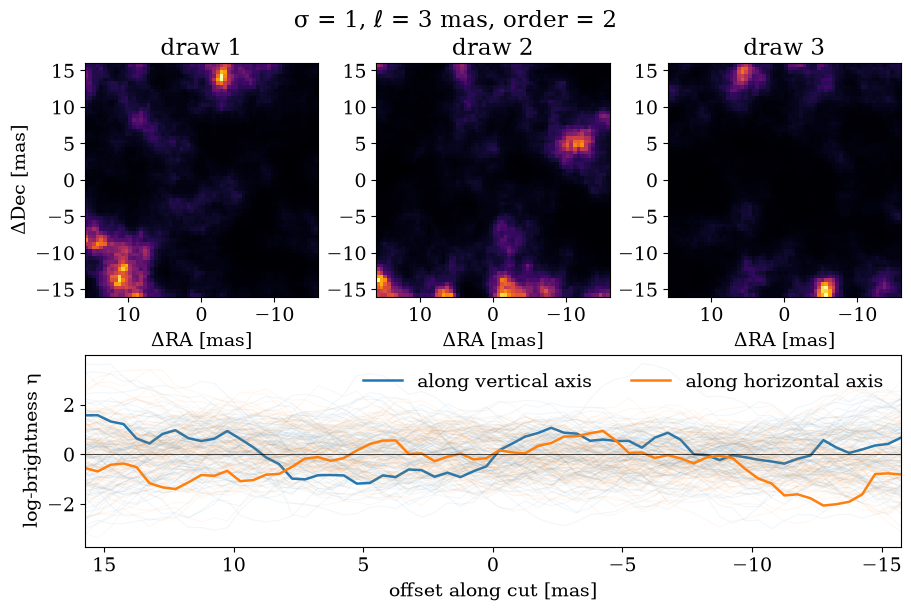

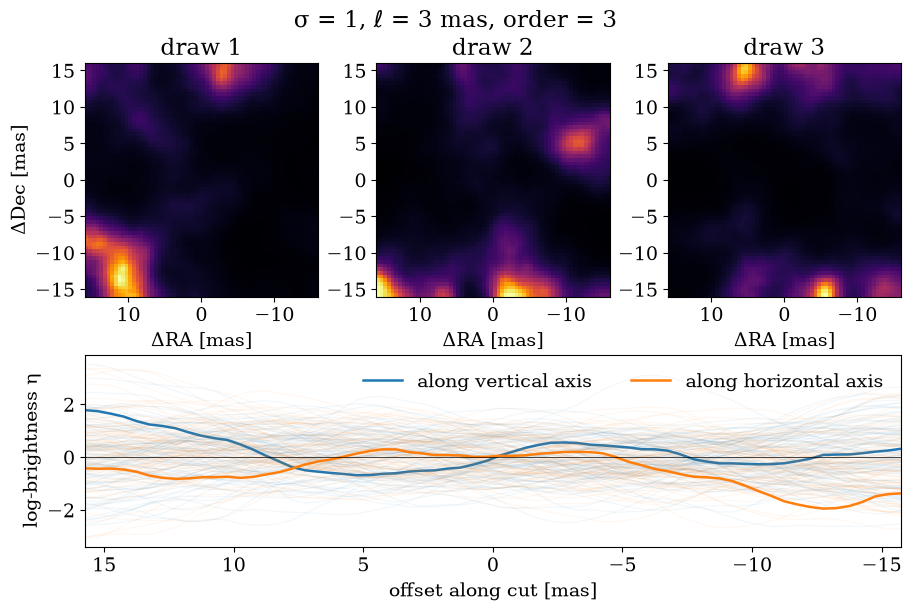

In [4]:
for order in (2, 3):
    plot_field_draws(prior(3.0, order), h, key, title=rf"σ = 1, $\ell$ = 3 mas, order = {order}")
    plt.show()

With `order=2` (ν = 1) the cuts are continuous but jagged on the pixel scale; with `order=3` (ν = 2) they are smooth curves, and the same patches become rounder and broader.

## A dictionary of IFT terms

The IFT papers write s for the signal (the unknown field), d for the data, R for the response (the forward model) and N for the noise covariance; for a linear model, d = Rs + n with prior s ~ N(0, S) and noise n ~ N(0, N). Two symbols clash with this page:

- IFT's **S** is the prior covariance matrix, which this page calls **Σ**; here S is the diagonal of Σ in the DCT basis.
- IFT's **D** is the posterior covariance; this page uses C for the DCT.

IFT's † is the adjoint, for real matrices the transpose ᵀ.

The "GP terminology" column follows Rasmussen & Williams (2006) where it covers the concept, and the wider literature otherwise (for example for variational inference). In the "In virgil" column, `env` is the name of an `Image` component in a `System` and `field` its `GaussianField`, so `env.log_brightness` is `field`.

| IFT / NIFTy term | GP terminology | In virgil |
|---|---|---|
| signal field, s | the unknown function; the latent function of a GP | the log-brightness η: the array `env.eta`, which calls `field.evaluate(pixel_scale_mas)` |
| response, R | forward model, measurement operator | `OIData.model(scene)`, which computes the observables of a `SourceModel` |
| signal covariance, S | prior covariance matrix, kernel matrix | Σ. Never formed as a matrix; it is set by `field.sigma`, `field.length_mas` and `field.order` |
| power spectrum, $P_s(k)$ | spectral density of a stationary kernel | $S_{jk}$: the array returned by `field_spectrum(shape, pixel_scale_mas, sigma, length_mas, order)` |
| harmonic space; harmonic partner | Fourier space; Fourier basis | the DCT-II coefficients, the space in which `field.latent` lives (the image's own Fourier space, not the (u, v) plane) |
| amplitude operator, A, with S = AA† | a square root of the covariance (like a Cholesky factor) | $C^\top \mathrm{diag}(\sqrt{S})$: in `field.evaluate`, the latents are multiplied by the square root of `field_spectrum(...)` and transformed with `idctn(..., type=2, norm="ortho")` |
| standardized coordinates, excitations, ξ | whitened latents; non-centred parameterization | z: the array `field.latent`, fitted at the path `"env.log_brightness.latent"` with standard-normal priors from `image_priors(scene)` |
| zero mode; offset | the mean level, the k = 0 Fourier component | `field_spectrum` sets `spectrum[0, 0]` to zero; the image's overall level is set by `env.flux` instead |
| information Hamiltonian, H(d, s) = −ln p(d, s) | negative log joint density; the loss function | the loss that `fit` minimizes, reported as `FitResult.info["loss"]`: half the sum of squares of `whitened_residuals(scene, data)` and of `field.latent`, up to a constant |
| partition function, Z(d) | evidence, marginal likelihood p(d) | `log_evidence(scene, data)` returns its logarithm, in the Laplace approximation |
| classical solution; minimum of H | MAP (maximum a posteriori) estimate | `fit(scene, priors, data)`, which returns the MAP as `FitResult.model` and `FitResult.values` |
| information source, j = R†N⁻¹d | back-projected, noise-weighted data; for a linear response, a dirty image | not formed. The closest analogue is `dirty_image(data, npix, pixel_scale_mas)`, which weights the data uniformly rather than by their errors |
| information propagator, D = (S⁻¹ + R†N⁻¹R)⁻¹ | posterior covariance | not returned for the latents. Its Laplace approximation, $(I + J^\top J)^{-1}$, is what `log_evidence` and `error_scale` use, through the determinant and eigenvalues of $J^\top J$ |
| Wiener filter, m = Dj | GP posterior mean; kriging | `FitResult.model`, the MAP. The MAP equals the posterior mean only for a linear model with Gaussian noise, and virgil's model is nonlinear |
| (Gibbs) free energy | variational free energy, the negative evidence lower bound (ELBO) | not computed |
| Fisher metric, M = J†N⁻¹J + 1 | Gauss–Newton curvature of the loss: the data's part plus the prior's (the identity, in whitened coordinates) | $J^\top J + I$, where J is the Jacobian of `whitened_residuals` with respect to `field.latent`. It is the matrix in each step of `fit(..., method="lm")`; because `whitened_residuals` already divides by the errors, N⁻¹ does not appear |
| MGVI (metric Gaussian variational inference) | variational inference with a Gaussian approximation whose covariance is the inverse Fisher metric | not implemented. virgil uses `fit` with the Laplace approximation, or NUTS through `numpyro_model` |
| geoVI (geometric variational inference) | variational inference after a nonlinear change of coordinates that makes the posterior closer to Gaussian | not implemented |
| critical filter | empirical-Bayes estimate of the power spectrum | a grid of `fit` and `log_evidence` over `sigma` and `length_mas`, as in [Imaging, part 3](imaging_gp.md); the spectral shape is fixed |
| correlated field model | a GP whose power spectrum is itself unknown and inferred, under a hierarchical prior | not implemented; `field_spectrum` has a fixed Matérn-like shape |
| log-normal field, s = e^φ | the exponential of a GP, used for positive quantities | `env.brightness`, the softmax of `env.eta` (unit sum; multiplied by `env.flux` in the visibilities) |
| Feynman diagrams; interaction terms | a perturbative expansion of a non-Gaussian posterior about a Gaussian one | not used |

Two terms are easy to misread:

- **Field.** A function on a continuous domain such as the sky, in practice discretized on a grid. A Gaussian random field and a Gaussian process are the same object, a distribution over functions: "random field" is the name in spatial statistics and physics, "Gaussian process" in machine learning.
- **Free energy.** In statistical mechanics, −ln Z. Variational inference approximates the posterior p(s | d) by a simpler q, minimizing $\mathrm{KL}(q \,\Vert\, p(s \mid d)) - \ln Z$, the negative ELBO, also called the variational free energy. Since the KL divergence is never negative, it is at least −ln Z, with equality when q is the exact posterior.

## Where virgil differs from NIFTy

virgil takes two ideas from IFT, whitened latents and a stationary field computed in a Fourier basis, but does not use NIFTy. It differs from NIFTy's standard image prior, the "correlated field model", in four ways:

| | virgil | NIFTy's correlated field |
|---|---|---|
| Spectrum | a fixed Matérn-like shape with two hyperparameters, σ and ℓ (`field_spectrum`) | inferred from the data: a power law plus smooth departures from it, controlled by hyperparameters named `fluctuations`, `flexibility`, `asperity` and `loglogavgslope` |
| Basis and edges | DCT-II, with reflecting edges (`idctn(..., type=2, norm="ortho")` in `field.evaluate`) | FFT, which is periodic, usually with zero-padding to keep the edges apart |
| Hyperparameters | chosen by the evidence on a grid (`log_evidence`), or sampled with NUTS (`numpyro_model`) | inferred together with the field, usually by MGVI or geoVI |
| Posterior | the MAP (`fit`) with a Laplace approximation (a Gaussian centred on the MAP), or NUTS samples (`numpyro_model`) | samples from MGVI or geoVI |

A fixed spectral shape has fewer hyperparameters, so it is quicker to fit and easier to interpret. A learned spectrum adapts to structure on several scales at once, such as a compact core in a diffuse halo.

The linear algebra is shared. In whitened coordinates the prior's curvature is the identity, so both codes build $J^\top J + I$: each Levenberg–Marquardt step solves a system in it, `log_evidence` takes its log-determinant, and MGVI uses its inverse as the covariance of a Gaussian approximation to the posterior and samples from it.

## Further reading

The GP references come first, since they use this page's terminology and make the IFT papers easier to map onto it.

**Gaussian processes**

- Rasmussen & Williams 2006, *Gaussian Processes for Machine Learning*, MIT Press, [free online](https://gaussianprocess.org/gpml/). Chapter 2 covers GP regression (IFT's Wiener filter), §4.2 the Matérn kernels, and chapter 5 the marginal likelihood and hyperparameters.

**GMRFs and the SPDE link**

- Lindgren, Rue & Lindström 2011, JRSS B 73, 423. Matérn fields as solutions of an SPDE whose discretization is a sparse GMRF, linking the "neighbouring pixels" and "power spectrum" descriptions of one prior.
- Rue & Held 2005, *Gaussian Markov Random Fields: Theory and Applications*, Chapman & Hall/CRC. The standard textbook.

**Evidence and hyperparameters**

- MacKay 1992, Neural Computation 4, 415, "Bayesian interpolation". The evidence framework behind `log_evidence` and `error_scale`.
- Bishop 2006, *Pattern Recognition and Machine Learning*, §3.5. A textbook account.

**Whitening and the non-centred parameterization**

- Papaspiliopoulos, Roberts & Sköld 2007, Statistical Science 22, 59. Centred and non-centred parameterizations of hierarchical models, and when each works better.
- Betancourt & Girolami, [arXiv:1312.0906](https://arxiv.org/abs/1312.0906), "Hamiltonian Monte Carlo for hierarchical models". Why the centred form makes funnels and how the non-centred form avoids them.

**Information field theory**

Read these with the dictionary above to hand.

- Enßlin, Frommert & Kitaura 2009, PRD 80, 105005, [arXiv:0806.3474](https://arxiv.org/abs/0806.3474). The founding paper: Hamiltonian, information source, propagator and Wiener filter.
- Enßlin 2019, Annalen der Physik 531, 1800127, [arXiv:1804.03350](https://arxiv.org/abs/1804.03350), "Information theory for fields". A review.
- Knollmüller & Enßlin 2019, [arXiv:1901.11033](https://arxiv.org/abs/1901.11033). MGVI.
- Frank, Leike & Enßlin 2021, Entropy 23, 853, [arXiv:2105.10470](https://arxiv.org/abs/2105.10470). geoVI.
- Edenhofer et al. 2024, JOSS 9, 6593, [arXiv:2402.16683](https://arxiv.org/abs/2402.16683). NIFTy.re, the JAX version of NIFTy, "a library for Gaussian processes and variational inference".
- The [NIFTy documentation](https://ift.pages.mpcdf.de/nifty/user/index.html), including its guide to the correlated field model.

**Imaging applications**

- Junklewitz et al. 2016, A&A 586, A76, [arXiv:1311.5282](https://arxiv.org/abs/1311.5282). RESOLVE, an IFT imaging algorithm for radio interferometry.
- Arras et al. 2022, Nature Astronomy 6, 259, [arXiv:2002.05218](https://arxiv.org/abs/2002.05218). Imaging M87* with resolve; the Methods describe the correlated field model.
- Tiede et al. 2026, ApJ 997, 262, [arXiv:2511.17706](https://arxiv.org/abs/2511.17706). HIBI: GMRF priors for VLBI imaging, in Comrade.jl.
- Thiébaut & Young 2017, JOSA A 34, 904, [arXiv:1708.08390](https://arxiv.org/abs/1708.08390). A tutorial on image reconstruction in optical interferometry, treating quadratic regularizers as Gaussian priors.